# The null family: does every test hold its size?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (size, power and the Monte Carlo error)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say how each of the twenty-one tests with a p-value is run on data where its null hypothesis holds, and read its size at 5% and 1% with its Monte Carlo error;
- apply the rule that decides whether a test holds its size (the exact probability where one exists, the one-sided bound otherwise) and reproduce the committed verdict, 19 of 21;
- read a p-value histogram as a check of the whole distribution of a test, and say why the discrete tests do not draw a flat one;
- explain from the engine's source why the Hosmer-Lemeshow test with $G-2$ degrees of freedom and the normal test over five years reject a right model too often, and check the explanation against the measured rates;
- read what a descriptive metric (the AUC and its standard error, the ECE) reads when the model is right, with the same performance measures.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `null` family of case C22 (validating the validator), the same artifact as notebook 01: 28 simulations, 128,000 repetitions, every dataset drawn from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`). The family runs each of the twenty-one tests that has a p-value on data where its null hypothesis holds at the boundary and its assumptions are met, so a rejection is always a false alarm.

- **File read:** `data/derived/C22/null.json`: `outputs.simulations` (one row per test and setting: rates, exact probabilities, p-value histogram, seed), `outputs.size_bounds`, `outputs.estimators` (the AUC and the ECE as estimators) and `impact` (the headline numbers the case reports).
- **Rows:** the keys ending in `@null` are the twenty-one tests in their default form. The other rows (`@fitted`, `@upper`, `@thin`, `@dev1`, `@dev1-extended`, `@null-20000`, `@n100`) are the settings the harness found to matter.

The next cell loads the artifact, indexes its rows, and prints the six panels of the family.

In [2]:
# Load the null family, index its rows by key and count the rows of each panel
LANG = "en"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}

print("baked by riskvalidation", null["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)
for panel in out["panels"]:
    n_rows = sum(1 for row in rows.values() if row["panel"] == panel["id"])
    print(f"{panel['label'][LANG]:32s} {n_rows} rows")

baked by riskvalidation 1.0.1 | installed 1.0.1
Calibration                      9 rows
Discrimination                   2 rows
Stability                        4 rows
Rating system                    2 rows
Rating transitions               4 rows
Settings that matter             7 rows
Counterparty credit risk         1 rows
IFRS 9 stages                    1 rows
LGD and EAD                      3 rows
Market: VaR back-tests           8 rows
Market: ES and distribution tests 4 rows
Portfolio credit risk            4 rows
Fairness                         2 rows
Machine learning                 2 rows


## Method

The size of a test is its rejection probability when the null holds, and the case estimates it as a rejection rate over $n$ repetitions (notebook 01). Two rules turn a rate into a verdict, and the case applies both at 5% and at 1%:

- where the test sees the data only through a default count, the exact rejection probability exists, and the test **holds its size** at the level $\alpha$ when that exact probability is at most $\alpha$;
- otherwise the simulated rate is compared with the one-sided bound $\alpha + z\sqrt{\alpha(1-\alpha)/n}$, $z = 3.09$ (Morris, White and Crowther, 2019, Table 6 for the standard error), and the test holds its size when the rate is inside it.

The steps read the twenty-one rows, apply the rule, look at the whole p-value distribution, and then explain the two clear failures from the engine's source.

### Step 1: the size of the twenty-one tests

The next cell prints, for each row ending in `@null`, the number of repetitions, the rejection rate at 5% with its Wilson interval, the rate at 1%, and the exact probabilities where the artifact carries them (the binomial, Jeffreys, Vasicek-corrected and traffic-lights tests).

In [3]:
# Print the rate at 5% with its Wilson interval, the rate at 1% and the exact sizes of every @null row
null_keys = [key for key in rows if key.endswith("@null")]
print(f"{'test':34s} {'n_rep':>6s} {'rate 5%':>8s} {'Wilson 95% interval':>23s} {'rate 1%':>8s} {'exact 5%':>9s} {'exact 1%':>9s}")
for key in null_keys:
    row = rows[key]
    r5, r1 = row["rates"]["p<0.05"], row["rates"]["p<0.01"]
    exact = row["exact"] or {}
    e5 = f"{exact['p<0.05']:.4f}" if exact else "-"
    e1 = f"{exact['p<0.01']:.4f}" if exact else "-"
    print(f"{row['label'][LANG]:34s} {row['n_rep']:6d} {r5['rate']:8.4f} {r5['wilson_low']:10.4f} to {r5['wilson_high']:7.4f} {r1['rate']:8.4f} {e5:>9s} {e1:>9s}")

test                                n_rep  rate 5%     Wilson 95% interval  rate 1%  exact 5%  exact 1%
Binomial                             4000   0.0455     0.0395 to  0.0524   0.0060    0.0479    0.0069
Jeffreys                             4000   0.0390     0.0334 to  0.0455   0.0112    0.0479    0.0138
Vasicek-corrected binomial           4000   0.0470     0.0409 to  0.0540   0.0077    0.0498    0.0096
Chi-square over grades               4000   0.0530     0.0465 to  0.0604   0.0127         -         -
Default profile                      4000   0.0370     0.0316 to  0.0433   0.0083         -         -
Hosmer-Lemeshow                      4000   0.0460     0.0399 to  0.0529   0.0097         -         -
Spiegelhalter                        4000   0.0540     0.0474 to  0.0614   0.0130         -         -
Normal test, five years              4000   0.0838     0.0756 to  0.0927   0.0405         -         -
Traffic lights, five years           4000   0.0365     0.0311 to  0.0428   0.003

### Step 2: which tests hold their size

The next cell applies the rule of the Method section to each row at both levels: the exact probability where the row has one, `within_size` on the simulated rate otherwise. It counts the verdicts, compares the count with the number the case reports in `impact.tests_within_bound`, and draws the 5% rates with their intervals against the nominal level and the size bound, green for a test that holds its size and red for one that does not.

tests that hold their size at 5% and 1%: 42 of 46 | reported by the case: 19
size bounds of 4000 repetitions: {'p<0.05': 0.0606, 'p<0.01': 0.0149}
does not hold: Jeffreys
does not hold: Normal test, five years
does not hold: Christoffersen independence
does not hold: Christoffersen conditional coverage


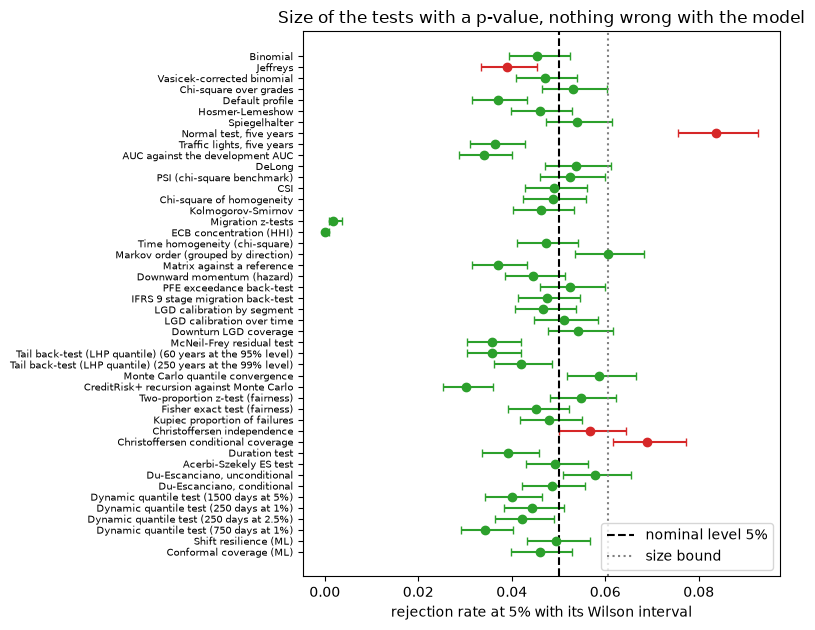

In [4]:
# Decide for each test whether it holds its size at both levels, count, and draw the 5% rates
from riskvalidation.harness import Rate, within_size

holds = {}
for key in null_keys:
    row = rows[key]
    verdicts = []
    for alpha in out["levels"]:
        rule = f"p<{alpha:g}"
        if row["exact"] is not None:
            verdicts.append(row["exact"][rule] <= alpha + 1e-12)
        else:
            c = row["rates"][rule]
            verdicts.append(within_size(Rate(c["rejections"], c["n"]), alpha))
    holds[key] = all(verdicts)

reported = null["impact"]["tests_within_bound"]["value"]
print("tests that hold their size at 5% and 1%:", sum(holds.values()), "of", len(holds), "|", "reported by the case:", int(reported))
print("size bounds of 4000 repetitions:", {rule: round(bound, 4) for rule, bound in out["size_bounds"].items()})
for key, ok in holds.items():
    if not ok:
        print("does not hold:", rows[key]["label"][LANG])

fig, ax = plt.subplots(figsize=(8, 6.4))
for i, key in enumerate(null_keys):
    c = rows[key]["rates"]["p<0.05"]
    ax.errorbar(c["rate"], i, xerr=[[c["rate"] - c["wilson_low"]], [c["wilson_high"] - c["rate"]]], fmt="o", capsize=3,
                color="tab:green" if holds[key] else "tab:red")
ax.axvline(0.05, color="black", linestyle="--", label="nominal level 5%")
ax.axvline(out["size_bounds"]["p<0.05"], color="gray", linestyle=":", label="size bound")
ax.set_yticks(range(len(null_keys)))
ax.set_yticklabels([rows[key]["label"][LANG] for key in null_keys], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("rejection rate at 5% with its Wilson interval")
ax.set_title("Size of the tests with a p-value, nothing wrong with the model")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Step 3: the whole p-value distribution

Under an exact continuous test, the p-value is uniform on $[0,1]$ when the null holds, so a histogram of 4,000 p-values is flat and its first bin counts the rejections at 5%. A test can hold its size at 5% and still be wrong elsewhere, and a discrete or one-sided test does not draw a flat histogram by design. The artifact keeps the 20-bin histogram of each row. The next cell draws eight of them; the dashed line is the flat expectation, 200 per bin.

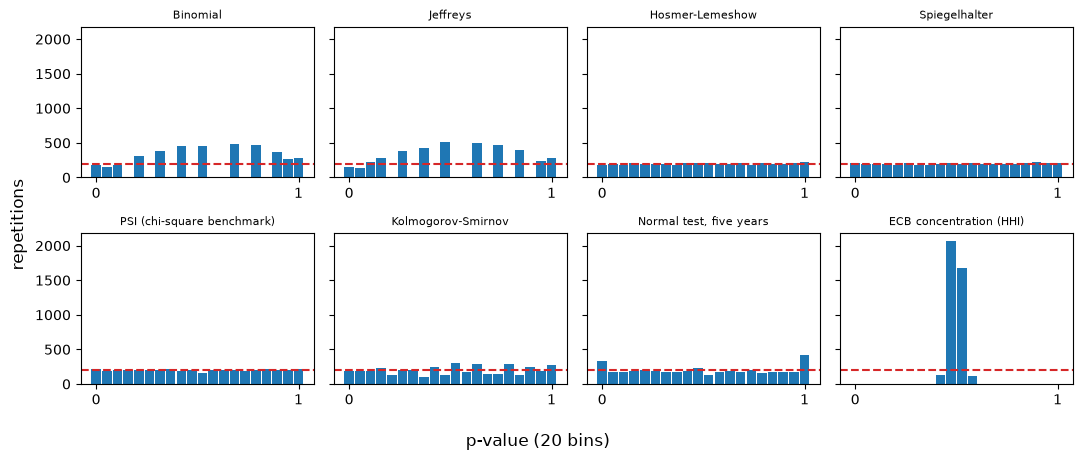

In [5]:
# Draw the committed p-value histograms of eight tests against the flat expectation
shown = ("pd.binomial@null", "pd.jeffreys@null", "pd.hosmer_lemeshow@null", "pd.spiegelhalter@null",
         "stability.psi@null", "stability.ks@null", "pd.normal_multiperiod@null", "rating.hhi@null")
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for ax, key in zip(axes.ravel(), shown):
    histogram = rows[key]["p_histogram"]
    ax.bar(range(len(histogram)), histogram, width=0.9, color="tab:blue")
    ax.axhline(sum(histogram) / len(histogram), color="tab:red", linestyle="--")
    ax.set_title(rows[key]["label"][LANG], fontsize=8)
    ax.set_xticks([0, len(histogram) - 1])
    ax.set_xticklabels(["0", "1"])
fig.supxlabel("p-value (20 bins)")
fig.supylabel("repetitions")
fig.tight_layout()
plt.show()

### Step 4: why Hosmer-Lemeshow with $G-2$ rejects a right model

The Hosmer-Lemeshow statistic groups the obligors in $G$ groups by predicted PD and sums the standardised gaps of observed and expected defaults (Hosmer and Lemeshow, 1980). Its reference distribution depends on how the PDs were obtained:

- for PDs **fitted on the same observations**, the original in-sample statistic, $\chi^2$ with $G-2$ degrees of freedom;
- for PDs **given before the outcomes**, which is the validator's case, each group's standardised gap is asymptotically an independent $\chi^2_1$ (the argument BCBS WP14 makes for its chi-square test over grades), so the reference is $\chi^2_G$.

The engine documents both choices in `pd_hosmer_lemeshow` (`fitted=False` uses $G$, `fitted=True` uses $G-2$). If the statistic is close to $\chi^2_{G}$ on a validation sample, a $G-2$ threshold is too low, and the size it produces is a tail probability we can compute: $P(\chi^2_{10} > \chi^2_{8,\,1-\alpha})$. The next cell computes it with SciPy and sets it beside the two committed rows.

In [6]:
# Tail probability of chi-square(10) beyond the chi-square(8) critical value, beside the committed sizes
for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
    wrong_reference = stats.chi2.sf(stats.chi2.ppf(1 - alpha, 8), 10)
    given = rows["pd.hosmer_lemeshow@null"]["rates"][rule]
    fitted = rows["pd.hosmer_lemeshow@fitted"]["rates"][rule]
    print(f"level {alpha:.2f} | G-2 threshold on a chi-square(10) statistic {wrong_reference:.4f} | measured with G-2 {fitted['rate']:.4f} (SE {fitted['se']:.4f}) | measured with G {given['rate']:.4f} (SE {given['se']:.4f})")

level 0.05 | G-2 threshold on a chi-square(10) statistic 0.1146 | measured with G-2 0.1098 (SE 0.0049) | measured with G 0.0460 (SE 0.0033)
level 0.01 | G-2 threshold on a chi-square(10) statistic 0.0284 | measured with G-2 0.0338 (SE 0.0029) | measured with G 0.0097 (SE 0.0016)


The committed rows are 4,000 repetitions of `LogisticPortfolio(n=5000)`, a logistic model of 5,000 obligors whose PDs are exactly right. The next cell draws one dataset from that generator, rebuilt from the configuration in the artifact, and runs the engine's test both ways on it, so the only difference is the degrees of freedom the engine records in the result.

In [7]:
# Draw one dataset from the committed generator and run the engine's test with G and with G-2 degrees of freedom
from riskvalidation.generators import LogisticPortfolio
from riskvalidation.validation import pd_hosmer_lemeshow

logit = LogisticPortfolio(**out["generators"]["logistic-5000"]["config"])
draw = logit.draw(np.random.default_rng(2024))
for fitted in (False, True):
    result = pd_hosmer_lemeshow(draw["defaults"], draw["pd"], fitted=fitted)
    print(f"fitted={fitted!s:5s} | statistic {result.statistic:.4f} | degrees of freedom {result.extras['dof']} | p-value {result.p_value:.4f}")
print("defaults in the dataset:", int(np.sum(draw["defaults"])), "of", len(draw["defaults"]))

fitted=False | statistic 9.7179 | degrees of freedom 10 | p-value 0.4656
fitted=True  | statistic 9.7179 | degrees of freedom 8 | p-value 0.2854
defaults in the dataset: 262 of 5000


The same statistic gives a smaller p-value with fewer degrees of freedom, which is the whole mechanism. The next cell replays the committed `@fitted` row, seed and all (about three seconds), to confirm that the 439 rejections at 5% are what the engine gives today.

In [8]:
# Replay the committed fitted=True row with its seed and compare the rejections
from riskvalidation.harness import simulate

row = rows["pd.hosmer_lemeshow@fitted"]
replay = simulate(row["test_id"], logit, n_rep=row["n_rep"], seed=row["seed"], test_kwargs={"fitted": True})
for rule in ("p<0.05", "p<0.01"):
    print(f"{rule} | replay {replay.rates[rule].rejections} | committed {row['rates'][rule]['rejections']}")
print("baked by", null["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

p<0.05 | replay 439 | committed 439
p<0.01 | replay 135 | committed 135
baked by 1.0.1 | installed 1.0.1


### Step 5: why the normal test over five years rejects a right model

The multi-period normal test of WP14 sums the yearly differences between the observed default rate and the PD, $e_t = d_t - \mathrm{PD}_t$, and divides by an estimate of their spread:

$$S = \frac{\sum_t e_t}{\sqrt{T}\,\hat\sigma}, \qquad \hat\sigma^2 = \frac{1}{T-1}\Big(\sum_t e_t^2 - \frac{1}{T}\big(\sum_t e_t\big)^2\Big)$$

and compares $S$ with the standard normal upper tail. The source of `pd_normal_multiperiod` shows that $\hat\sigma$ is the sample standard deviation of the $T$ yearly differences, so $S = \sqrt{T}\,\bar e / \hat\sigma$ is the one-sample $t$ statistic with $T-1$ degrees of freedom. With $T = 5$ years it has four degrees of freedom, and its tails are heavier than the normal's the test uses. If that is the cause, the size should be the $t_4$ tail beyond the normal critical value. The next cell computes that tail and sets it beside the committed rates. The agreement is a consistency check, not an identity: the yearly differences are scaled counts, not exactly normal.

In [9]:
# Tail of the t distribution with four degrees of freedom beyond the normal critical value, beside the committed sizes
row = rows["pd.normal_multiperiod@null"]
for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
    critical = stats.norm.isf(alpha)
    t_tail = stats.t.sf(critical, 4)
    c = row["rates"][rule]
    gap = (c["rate"] - t_tail) / np.sqrt(t_tail * (1 - t_tail) / c["n"])
    print(f"level {alpha:.2f} | normal critical value {critical:.4f} | t(4) tail {t_tail:.4f} | measured {c['rate']:.4f} (SE {c['se']:.4f}) | z {gap:+.2f}")

level 0.05 | normal critical value 1.6449 | t(4) tail 0.0877 | measured 0.0838 (SE 0.0044) | z -0.88
level 0.01 | normal critical value 2.3263 | t(4) tail 0.0403 | measured 0.0405 (SE 0.0031) | z +0.07


### Step 6: the traffic-lights test and its tie rule

The traffic-lights test colours each year by its standardised default rate and rejects when the colour profile is bad enough. A year with exactly the expected number of defaults sits on a colour boundary, and the engine offers two rules for it (`ties="lower"`, the printed mapping, and `ties="upper"`, the one WP14's own simulation used). Both are exact computations, no simulation needed, and the engine exposes them as `traffic_lights_rejection_probability`. The next cell computes the exact size of both rules for five independent years of 1,000 obligors at a PD of 3%, and compares the first with the committed row. The `@upper` row in the settings panel carries the second.

In [10]:
# Exact size of the traffic-lights test under the two tie rules, beside the committed exact values
from riskvalidation.harness import traffic_lights_rejection_probability

for ties, key in (("lower", "pd.traffic_lights@null"), ("upper", "pd.traffic_lights@upper")):
    for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
        exact = traffic_lights_rejection_probability([1000] * 5, 0.03, alpha, pd_true=0.03, ties=ties)["probability"]
        c = rows[key]["rates"][rule]
        print(f"ties={ties:5s} | level {alpha:.2f} | exact {exact:.4f} | committed exact {rows[key]['exact'][rule]:.4f} | simulated {c['rate']:.4f}")

ties=lower | level 0.05 | exact 0.0379 | committed exact 0.0379 | simulated 0.0365
ties=lower | level 0.01 | exact 0.0074 | committed exact 0.0074 | simulated 0.0035
ties=upper | level 0.05 | exact 0.0603 | committed exact 0.0603 | simulated 0.0635
ties=upper | level 0.01 | exact 0.0113 | committed exact 0.0113 | simulated 0.0140


### Step 7: the settings that matter

The `settings` panel holds the rows the harness added because a default turned out to matter: the Hosmer-Lemeshow degrees of freedom (step 4), the tie rule (step 6), a best grade that expects under one default, the development AUC estimated instead of known, the order test on 20,000 repetitions, and the PSI with samples of 100 judged by its two rules of thumb. The next cell prints their rates; the rules of thumb appear as `metric>0.1` and `metric>0.25`.

In [11]:
# Print the rates of the settings panel, with the rules of thumb of the PSI when present
setting_note = {
    "fitted": "G - 2 degrees of freedom (fitted=True)",
    "upper": "the upper tie rule that the WP14 simulation used",
    "thin": "a best grade expecting under one default",
    "dev1": "the development AUC estimated on an equal sample (ECB form)",
    "dev1-extended": "the same with the development variance added",
    "null-20000": "the order test on 20000 repetitions",
    "n100": "two samples of 100 with the PSI rules of thumb",
}
for key, row in rows.items():
    if row["panel"] != "settings":
        continue
    parts = [f"{rule} {row['rates'][rule]['rate']:.4f}" for rule in row["rates"]]
    print(f"{key:36s} n_rep {row['n_rep']:6d} | " + " | ".join(parts))
    print(f"   {setting_note[key.split('@')[1]]}")

pd.hosmer_lemeshow@fitted            n_rep   4000 | p<0.05 0.1098 | p<0.01 0.0338
   G - 2 degrees of freedom (fitted=True)
pd.traffic_lights@upper              n_rep   4000 | p<0.05 0.0635 | p<0.01 0.0140
   the upper tie rule that the WP14 simulation used
pd.chi2_grades@thin                  n_rep   4000 | p<0.05 0.0568 | p<0.01 0.0173
   a best grade expecting under one default
disc.auc_vs_initial@dev1             n_rep   4000 | p<0.05 0.1158 | p<0.01 0.0452
   the development AUC estimated on an equal sample (ECB form)
disc.auc_vs_initial@dev1-extended    n_rep   4000 | p<0.05 0.0530 | p<0.01 0.0105
   the same with the development variance added
rating.markov_order@null-20000       n_rep  20000 | p<0.05 0.0505 | p<0.01 0.0106
   the order test on 20000 repetitions
stability.psi@n100                   n_rep   4000 | p<0.05 0.0698 | p<0.01 0.0205 | metric>0.1 0.8498 | metric>0.25 0.2285
   two samples of 100 with the PSI rules of thumb


### Step 8: a descriptive metric when the model is right

Not every output of the engine is a test. The AUC and the ECE are estimates, and a validator reads them with their own performance measures: bias, empirical standard error, the engine's model standard error, and the coverage of its interval, each with a Monte Carlo error (Morris, White and Crowther, 2019, Table 6). The artifact holds two: the AUC and its ECB standard error on binormal scores of known AUC, and the ECE on a model whose PDs are exactly right, where the truth is 0. The next cell prints them. The cell after it recomputes the AUC performance on 400 fresh draws with the engine's `estimator_performance`, to show the call, not to replace the committed 4,000.

In [12]:
# Print the committed performance measures of the AUC and of the ECE when the model is right
auc = out["estimators"]["auc"]
ece = out["estimators"]["ece_when_right"]
print("AUC, repetitions:", auc["n"], "|", "truth:", round(auc["truth"], 5))
print(f"  bias {auc['bias']:+.5f} (MCSE {auc['bias_mcse']:.5f}) | empirical SE {auc['empirical_se']:.5f} | model SE {auc['model_se']:.5f} ({auc['model_se_relative_error_pct']:+.2f}% ± {auc['model_se_relative_error_mcse_pct']:.2f})")
print(f"  coverage of the 95% interval {auc['coverage']:.4f} (MCSE {auc['coverage_mcse']:.4f})")
print("ECE when the PDs are right, repetitions:", ece["n"], "|", "truth:", ece["truth"])
print(f"  mean {ece['mean']:.5f} | bias {ece['bias']:+.5f} (MCSE {ece['bias_mcse']:.5f}) | RMSE {ece['rmse']:.5f}")

AUC, repetitions: 4000 | truth: 0.80193
  bias +0.00074 (MCSE 0.00028) | empirical SE 0.01790 | model SE 0.01788 (-0.15% ± 1.12)
  coverage of the 95% interval 0.9395 (MCSE 0.0038)
ECE when the PDs are right, repetitions: 1000 | truth: 0.0
  mean 0.00672 | bias +0.00672 (MCSE 0.00006) | RMSE 0.00694


The committed numbers come from 4,000 repetitions. The next cell shows the engine's call on 400 new draws of the same generator: the AUC and its ECB standard error from `auc_with_variance`, then `estimator_performance` with the model standard error and the 95% interval. Fewer draws give larger Monte Carlo errors, and the performance function reports them.

In [13]:
# Recompute the AUC performance on 400 fresh draws of the committed generator with estimator_performance
from riskvalidation.generators import BinormalScores
from riskvalidation.harness import estimator_performance
from riskvalidation.validation.discrimination import auc_with_variance

binormal = BinormalScores(**out["generators"]["binormal-150"]["config"])
estimates, model_se = [], []
for child in np.random.SeedSequence(11).spawn(400):
    sample = binormal.draw(np.random.default_rng(child))
    auc_hat, variance, _, _ = auc_with_variance(sample["risk"], sample["defaults"])
    estimates.append(auc_hat)
    model_se.append(np.sqrt(variance))

estimates, model_se = np.array(estimates), np.array(model_se)
fresh = estimator_performance(estimates, binormal.truth()["auc_current"], model_se=model_se,
                              lower=estimates - 1.96 * model_se, upper=estimates + 1.96 * model_se)
print("fresh draws:", fresh["n"], "|", "bias", f"{fresh['bias']:+.5f} (MCSE {fresh['bias_mcse']:.5f})", "|", "coverage", f"{fresh['coverage']:.4f} (MCSE {fresh['coverage_mcse']:.4f})")
print("model SE relative error:", f"{fresh['model_se_relative_error_pct']:+.2f}% ± {fresh['model_se_relative_error_mcse_pct']:.2f}")

fresh draws: 400 | bias -0.00038 (MCSE 0.00094) | coverage 0.9350 (MCSE 0.0123)
model SE relative error: -4.57% ± 3.40


## Results

- **Nineteen of twenty-one tests hold their size at 5% and 1%.** The recomputation gives the count the case reports. The two that do not are the Jeffreys test and the normal test over five years. The Jeffreys test is red in the figure because of its 1% level: the exact probability that it rejects at 1% on 1,000 obligors at a PD of 1% is 1.38%, above 1%, although its simulated rate at 5% (3.90%) is below the nominal level. The normal test over five years rejects 8.38% at 5% and 4.05% at 1%, outside the bound of 6.06% and 1.49%.
- **Two tests hold their size by being conservative, not by being calibrated.** The migration z-tests reject 0.18% at 5% and the ECB concentration test 0.00%. The histogram of the concentration test shows why: its p-values pile up around one half, so it almost never reaches a small p-value even on a change. Holding the size says nothing about power, and notebook 06 measures both.
- **The histograms separate what the rates cannot.** Hosmer-Lemeshow, Spiegelhalter and the PSI draw flat histograms. The binomial and Jeffreys tests draw lumps and gaps because a default count takes few values, which is also why their exact size is not the nominal level. The normal test has extra mass in the first and last bins, the signature of a statistic compared with a distribution that is too light.
- **The two failures have mechanisms we checked.** Hosmer-Lemeshow with $G-2$ degrees of freedom on PDs set before the outcomes would reject at the tail of a $\chi^2_{10}$ beyond the $\chi^2_8$ critical value: 11.46% at 5% and 2.84% at 1%, against 10.98% and 3.38% measured. The engine's default for given PDs is $G$ degrees of freedom, which measures 4.60% and 0.97%. The same statistic on one drawn dataset gives p 0.466 with 10 degrees of freedom and 0.285 with 8. The normal test is a one-sample $t$ statistic with four degrees of freedom compared with normal critical values: the $t_4$ tail beyond the normal critical value is 8.77% at 5% and 4.03% at 1%, against 8.38% and 4.05% measured (gaps of -0.88 and +0.07 standard errors). That is consistent with the cause, not a proof of it.
- **A default is a measurement too.** The traffic-lights exact size is 3.79% at 5% with the printed tie rule and 6.03% with the upper rule, the one WP14's simulation used. A chi-square over grades whose best grade expects 0.6 defaults rejects 5.68% at 5% and 1.73% at 1%, above the 1% bound. The ECB AUC test rejects 11.58% at 5% when the development AUC was estimated on a sample as large as the current one, and 5.30% when the development variance is added. Samples of 100 give the PSI 0.10 rule a false-alarm rate of 84.98% and the 0.25 rule 22.85%, against 6.98% for the chi-square benchmark at 5%.
- **A metric that is zero when the model is right is not.** The ECE of a right model with 5,000 obligors averages 0.0067, a bias of more than 100 Monte Carlo standard errors, so a small ECE is not evidence of miscalibration by itself. The ECB standard error of the AUC is right on average (-0.15% relative error with a Monte Carlo error of 1.12 points) and its 95% interval covers 93.95% (Monte Carlo error 0.38 points). The 400 fresh draws agree within their larger error: a relative error of -4.57 ± 3.40 and a coverage of 93.50%.

What this notebook does not show: the power of any test, what happens when the model is wrong in a known way (notebook 03), or when the defaults are correlated (notebook 04). A test that holds its size here holds it on these generators and their assumptions, not on every portfolio.

## Summary

- The size of a test is measured on data where its null holds; a test holds its size when its exact probability, or its simulated rate against a one-sided bound, is at most the level.
- Nineteen of the twenty-one tests with a p-value hold their size at 5% and 1%; the Jeffreys test (exact size 1.38% at 1%) and the normal test over five years (8.38% at 5%) do not.
- A p-value histogram checks the whole distribution: flat for the continuous tests, lumpy for the count tests, heavy at both ends for a statistic compared with a distribution that is too light.
- The two failures have mechanisms in the engine's source that the measured rates agree with: $G-2$ degrees of freedom for given PDs, and a $t_4$ statistic read against normal critical values.
- Defaults are measurements: the tie rule of the traffic lights, a thin grade, an estimated development AUC and the PSI rules of thumb each move the size, and a descriptive metric such as the ECE has a bias when the model is right.

**What to try next.** Change the seed of the dataset drawn in step 4 and rerun the cell a few times to see the $G$ and $G-2$ p-values move together; then read notebook 03, which plants defects and measures power.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the normal test over several periods, the traffic-lights test and the chi-square test over grades. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 to 2.5.5 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.